# Week over week change, with moving averages

**Objective.** Show how average glucose, the size of the swings, and the time spent below 70 change from week to week, and whether the last weeks are calmer than the first.

Method references: Knuth (1984, *Computer Journal* 27:97-111) and Rule et al. (2019, *PLoS Computational Biology* 15:e1007007). Times of day are not used here, so the clock question in notebook time_of_day does not matter.

## Step 1. Read the file and summarise each day

In [1]:
source("src/read_glucose.R")
source("src/daily_summary.R")
source("src/moving_average.R")
glucose <- read_glucose("../data/lingo-glucose-2026-09-27-to-2026-11-17.csv")
daily <- daily_summary(glucose)
sum(daily$complete)
daily$day[!daily$complete]

[1] 43
[1] "2026-09-27" "2026-10-10" "2026-10-11" "2026-10-25" "2026-10-26"
[6] "2026-11-02" "2026-11-03" "2026-11-04" "2026-11-17"


**Explanation**

* The three `source(...)` lines load the functions `read_glucose` (see notebook time_of_day), `daily_summary` and `moving_average`.
* `daily_summary(glucose)` makes one row for every calendar day from the first to the last, with the number of readings, the mean, the standard deviation, and the percent of readings below 70. The standard deviation measures how far readings typically are from the mean, so a larger value means bigger swings. A day with no readings gets missing values.
* A day is marked `complete` when it has at least 230 of the 288 readings a full day would have, which is about 80 percent. The rest are partial days from sensor problems.
* `sum(daily$complete)` counts the complete days. `daily$day[!daily$complete]` lists the days that are not complete. The sign `!` means "not".

**Result.** 43 of the 52 days from 2026-09-27 to 2026-11-17 are complete. The 9 that are not are 09-27, 10-10, 10-11, 10-25, 10-26, 11-02, 11-03, 11-04 and 11-17. There are no readings at all on 11-03.

## Step 2. Summarise each week and its change from the week before

In [2]:
weekly <- weekly_summary(glucose)
round(weekly, 1)

           days readings mean   sd below70 above140 change_mean change_sd
2026-09-27    7     1917 81.7 20.3    33.9      1.9          NA        NA
2026-10-04    7     1882 82.4 20.6    26.2      2.3         0.7       0.3
2026-10-11    7     1810 83.1 18.1    18.1      1.7         0.6      -2.5
2026-10-18    7     2016 86.1 15.3     7.2      0.6         3.0      -2.7
2026-10-25    7     1745 89.6 16.2     6.6      1.1         3.6       0.9
2026-11-01    6     1402 90.8 22.8    15.0      3.4         1.1       6.6
2026-11-08    7     2016 94.9 18.2     3.0      2.6         4.1      -4.6
2026-11-15    3      770 96.5 13.7     0.0      1.2         1.7      -4.5
           change_below70
2026-09-27             NA
2026-10-04           -7.7
2026-10-11           -8.2
2026-10-18          -10.8
2026-10-25           -0.7
2026-11-01            8.4
2026-11-08          -12.0
2026-11-15           -3.0


**Explanation**

* `weekly_summary(glucose)` groups the readings into weeks that start on a Sunday, beginning 2026-09-27, and gives for each week the number of days with readings, the number of readings, the mean, the standard deviation, the percent of readings below 70, and the percent above 140.
* The columns starting with `change_` are this week minus the week before. They are missing for the first week. For example, `change_mean` of 3.0 means the mean is 3 mg/dL higher than the week before.
* The row names are the first day (Sunday) of each week. `round(weekly, 1)` rounds to one decimal place.
* The last week has only 3 days, and the week of 2026-11-01 has 6 days, so their numbers rest on fewer readings.

**Result.** From the first to the last week the mean rose from 81.7 to 96.5 mg/dL. It rose in every one of the 7 week to week changes, by 0.6 to 4.1 mg/dL each time. The percent of readings below 70 fell from 33.9 to 0.0, with one step back in the week of 2026-11-01 (15.0, up 8.4). That week also has the largest swings (standard deviation 22.8, up 6.6) and only 6 days of readings. The standard deviation was 20.3 in the first week and 13.7 in the last, which has 3 days.

## Step 3. Seven day moving averages

In [3]:
daily$mean7  <- moving_average(daily$mean, daily$complete)
daily$sd7    <- moving_average(daily$sd, daily$complete)
daily$low7   <- moving_average(daily$below70, daily$complete)
tail(daily[, c("day", "mean", "mean7", "sd", "sd7")], 7)

          day     mean    mean7       sd      sd7
46 2026-11-11 89.51389 90.88166 14.87133 18.49536
47 2026-11-12 92.59028 91.14980 13.72320 17.61143
48 2026-11-13 98.20139 93.38343 22.64699 17.68202
49 2026-11-14 99.59028 94.85516 22.82700 17.46465
50 2026-11-15 96.39583 95.68353 12.58572 16.75070
51 2026-11-16 98.76736 95.76835 13.30812 16.65205
52 2026-11-17 93.44845 95.84317 15.22474 16.66039


**Explanation**

* A moving average smooths day to day noise. For each day it is the average of that day and the 6 days before it, so the value for a day uses only that day and earlier days.
* `moving_average(values, ok)` uses only the days marked complete in `ok`, and gives a missing value when fewer than 4 complete days are in the window.
* `mean7` is the moving average of the daily mean, `sd7` of the daily standard deviation, and `low7` of the daily percent below 70.
* `tail(..., 7)` shows the last 7 rows, and `daily[, c(...)]` keeps only the columns we name.

## Step 4. Plot the days and their moving averages

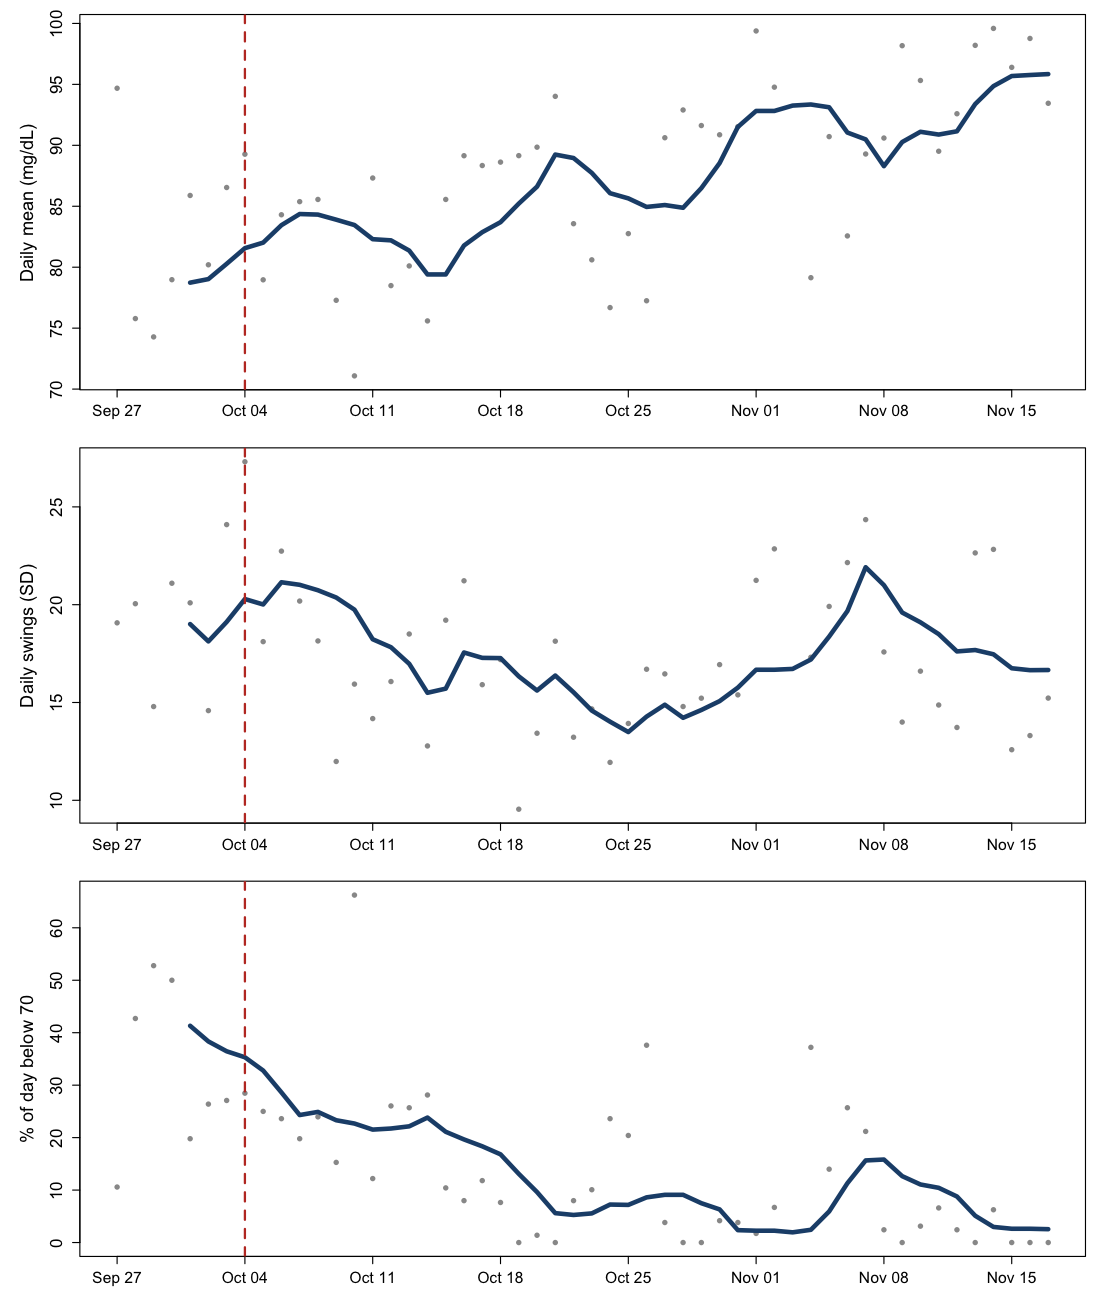

In [4]:
vimpat <- as.Date("2026-10-04")
panel <- function(values, smooth, label, line) {
  plot(daily$day, values, pch = 16, col = "gray60", xlab = "", ylab = label,
       cex.lab = 1.5, cex.axis = 1.4, xaxt = "n")
  axis.Date(1, at = seq(as.Date("2026-09-27"), as.Date("2026-11-17"), by = 7),
            format = "%b %d", cex.axis = 1.3)
  lines(daily$day, smooth, lwd = 4, col = "#1f4e79")
  abline(v = vimpat, lty = 2, lwd = 2, col = "#c0392b")
  if (!is.null(line)) abline(h = line, lty = 3)
}
par(mfrow = c(3, 1), mar = c(3, 5.5, 1, 1))
panel(daily$mean, daily$mean7, "Daily mean (mg/dL)", NULL)
panel(daily$sd, daily$sd7, "Daily swings (SD)", NULL)
panel(daily$below70, daily$low7, "% of day below 70", NULL)

**Explanation**

* `panel(...)` is a small function of our own that draws one plot: the gray dots are the individual days, the blue line is the 7 day moving average, and the red dashed vertical line is 2026-10-04, when Vimpat was started (date from the caregiver). Writing it once lets us draw the three plots with the same layout.
* `par(mfrow = c(3, 1))` puts three plots in one picture, one above the other. `mar` sets the margins.
* `plot(x, y, pch = 16, ...)` draws dots. `axis.Date(1, at = ..., format = "%b %d")` labels the horizontal axis with a date every 7 days. `lines(...)` adds the moving average. `abline(v = ...)` draws a vertical line.
* Partial days are drawn as dots too, so a dot from a day with few readings can sit far from the line.

## Step 5. Compare the first three weeks with the last three

In [5]:
done <- daily[daily$complete, ]
first <- head(done, 21)
last  <- tail(done, 21)
summarise <- function(x) {
  c(median_mean = median(x$mean), median_sd = median(x$sd),
    median_below70 = median(x$below70), highest_sd = max(x$sd))
}
compare <- data.frame(rbind(first_21_days = summarise(first),
                            last_21_days = summarise(last)))
compare$from <- c(format(min(first$day)), format(min(last$day)))
compare$to   <- c(format(max(first$day)), format(max(last$day)))
round(compare[, 1:4], 1)
compare[, c("from", "to")]
p_values <- c(mean = wilcox.test(first$mean, last$mean)$p.value,
              sd = wilcox.test(first$sd, last$sd)$p.value,
              below70 = wilcox.test(first$below70, last$below70)$p.value)
round(p_values, 4)

              median_mean median_sd median_below70 highest_sd
first_21_days        85.4      18.1           24.0       27.3
last_21_days         91.5      15.4            3.8       24.3
                    from         to
first_21_days 2026-09-28 2026-10-20
last_21_days  2026-10-22 2026-11-16
   mean      sd below70 
 0.0000  0.3825  0.0001 


**Explanation**

* `done <- daily[daily$complete, ]` keeps the complete days only. `head(done, 21)` takes the first 21 of them and `tail(done, 21)` the last 21.
* `summarise(x)` is a small function of our own. For one group of days it gives the median of the daily mean, the median of the daily standard deviation, the median of the daily percent below 70, and the largest daily standard deviation. The median is the middle value, so one unusual day does not change it much.
* `rbind(a, b)` stacks the two groups into a table, and `data.frame(...)` makes it a data frame. The names to the left of each `=` become the row names.
* `compare$from` and `compare$to` add the first and last date of each group. The first group is the first 21 complete days and the last group is the last 21.
* `wilcox.test(a, b)` is the Wilcoxon rank sum test (Wilcoxon 1945, *Biometrics Bulletin* 1:80-83). It asks whether the values in one group tend to be larger than in the other. `$p.value` pulls out its p value. A small p value means the difference would be unlikely if both groups came from the same pattern. We run it on three measures, so each p value should be read with that in mind, and none is a measure of how large a change is.

**Result.** Between the first 21 complete days (2026-09-28 to 2026-10-20) and the last 21 (2026-10-22 to 2026-11-16):

* The median daily percent below 70 fell from 24.0 to 3.8 (p = 0.0001).
* The median daily mean rose from 85.4 to 91.5 mg/dL (p below 0.0001).
* The median daily standard deviation, our measure of swings, went from 18.1 to 15.4, but p = 0.38. These data do not show a reliable difference in swings between the two groups. The largest single day was 27.3 in the first group and 24.3 in the last.

The p values use an approximation because some values are tied. In the moving average, swings dipped to about 13.5 around 2026-10-25, rose to about 22 around 2026-11-07, and were about 16.7 on 2026-11-17.

So the lows have calmed down clearly. The swings are somewhat lower in the median but are not steady week to week, and the week of 2026-11-01 was a step backward.